# Lab #5


Name: Maan Abdullah Alghamdi
ID: 2240001433
Course: ARTI 403 - Image Processing

## Spatial Filtering
I implemented the three assessment tasks and the unsharp masking example using the supplied parrot image. I processed the full-resolution RGB image and scaled only the plots for display.

I can reproduce the results by running all cells from the Lab5 folder.

## Libraries
I use OpenCV, NumPy, and Matplotlib for the following tasks.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


## Procedural steps Task 1 Unsharp Masking
I follow the manual's example with sigma = 2 and amount = 1.5. I subtract the blurred image from the original to form a mask, then add the scaled mask to sharpen the image.

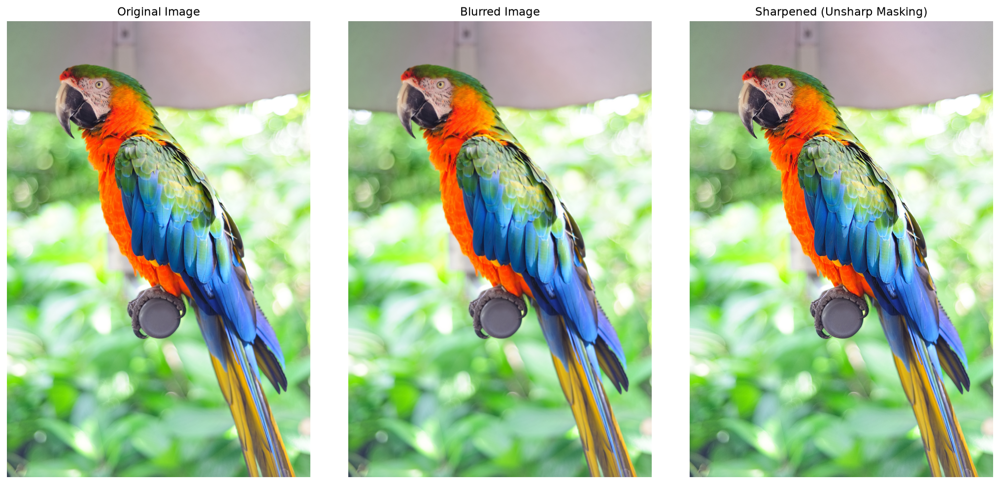

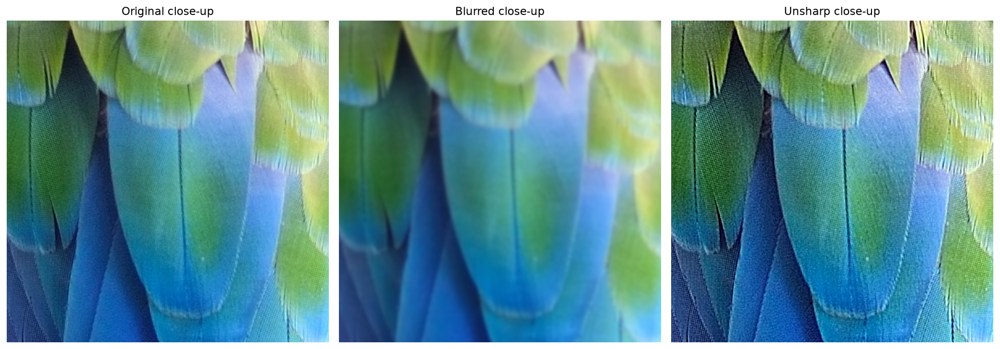

In [2]:
# Read the image and convert BGR to RGB
image = cv2.imread('images/parrot.png')
if image is None:
    raise FileNotFoundError('images/parrot.png was not found')
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
image_float = image.astype(np.float32) / 255.0

# Gaussian sigma and sharpening amount
sigma = 2
amount = 1.5

# Apply Gaussian blur
blurred = cv2.GaussianBlur(image_float, (0, 0), sigmaX=sigma, sigmaY=sigma)

# Perform unsharp masking
sharpened = np.clip(image_float + amount * (image_float - blurred), 0, 1)

fig, ax = plt.subplots(1, 3, figsize=(15, 7))
ax[0].imshow(image)
ax[0].set_title('Original Image')
ax[0].axis("off")

ax[1].imshow(blurred)
ax[1].set_title('Blurred Image')
ax[1].axis("off")

ax[2].imshow(sharpened)
ax[2].set_title('Sharpened (Unsharp Masking)')
ax[2].axis("off")

plt.tight_layout()
plt.show()

# Close-up of the same feather region to make the filter effect visible
x, y, size = 1100, 1350, 400
fig, ax = plt.subplots(1, 3, figsize=(15, 7))
ax[0].imshow((image)[y:y+size, x:x+size])
ax[0].set_title('Original close-up')
ax[0].axis("off")

ax[1].imshow((blurred)[y:y+size, x:x+size])
ax[1].set_title('Blurred close-up')
ax[1].axis("off")

ax[2].imshow((sharpened)[y:y+size, x:x+size])
ax[2].set_title('Unsharp close-up')
ax[2].axis("off")

plt.tight_layout()
plt.show()


## Task 1 Assessment Box Filter
I convolve the image with a normalized 7 x 7 box filter and show the original and smoothed images side by side. The filter averages 49 pixels and softens fine details.

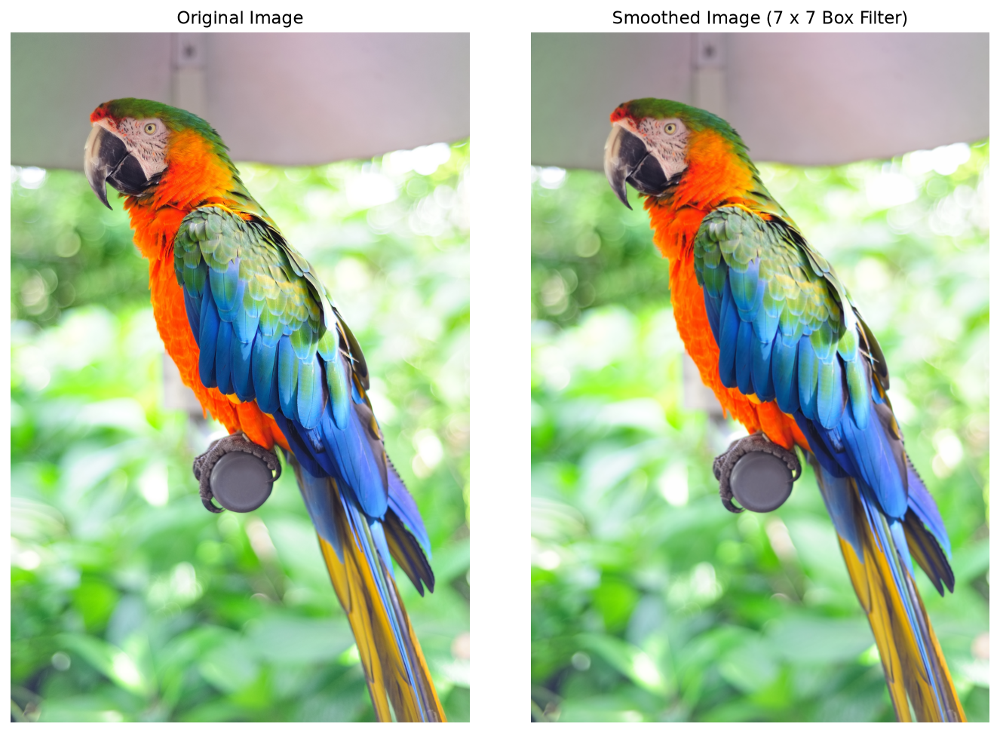

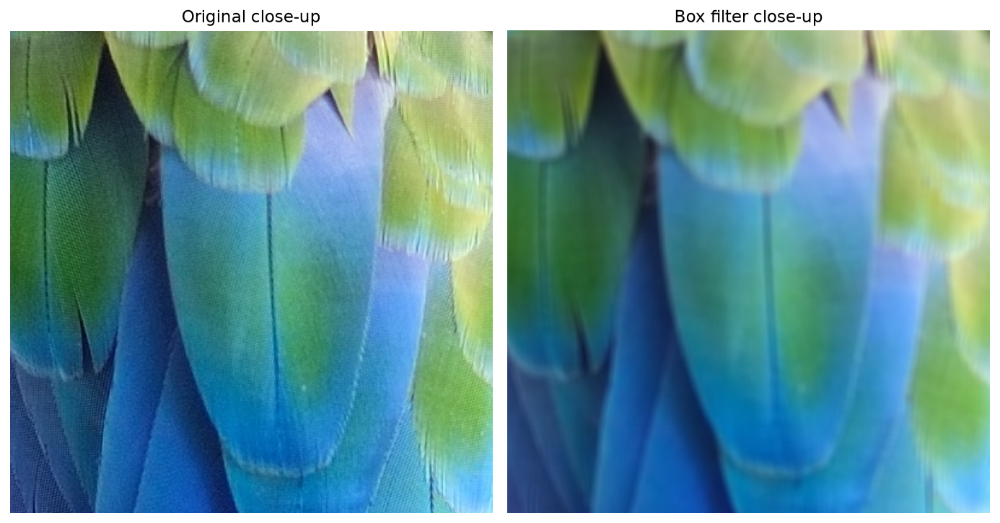

In [3]:
# Read the image and convert BGR to RGB
image = cv2.imread('images/parrot.png')
if image is None:
    raise FileNotFoundError('images/parrot.png was not found')
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
image_float = image.astype(np.float32) / 255.0

# Define the normalized 7 x 7 box kernel
kernel = np.ones((7, 7), dtype=np.float32) / 49.0

# Apply the box filter
smoothed = cv2.filter2D(image_float, -1, kernel)

fig, ax = plt.subplots(1, 2, figsize=(10, 7))
ax[0].imshow(image)
ax[0].set_title('Original Image')
ax[0].axis("off")

ax[1].imshow(np.clip(smoothed, 0, 1))
ax[1].set_title('Smoothed Image (7 x 7 Box Filter)')
ax[1].axis("off")

plt.tight_layout()
plt.show()

# Close-up of the same feather region to make the filter effect visible
x, y, size = 1100, 1350, 400
fig, ax = plt.subplots(1, 2, figsize=(10, 7))
ax[0].imshow((image)[y:y+size, x:x+size])
ax[0].set_title('Original close-up')
ax[0].axis("off")

ax[1].imshow((np.clip(smoothed, 0, 1))[y:y+size, x:x+size])
ax[1].set_title('Box filter close-up')
ax[1].axis("off")

plt.tight_layout()
plt.show()


## Task 2 Assessment Gaussian Filters
I apply a 5 x 5 Gaussian filter and a 21 x 21 Gaussian filter independently to the original image. I show all three images side by side. The larger kernel produces stronger smoothing.

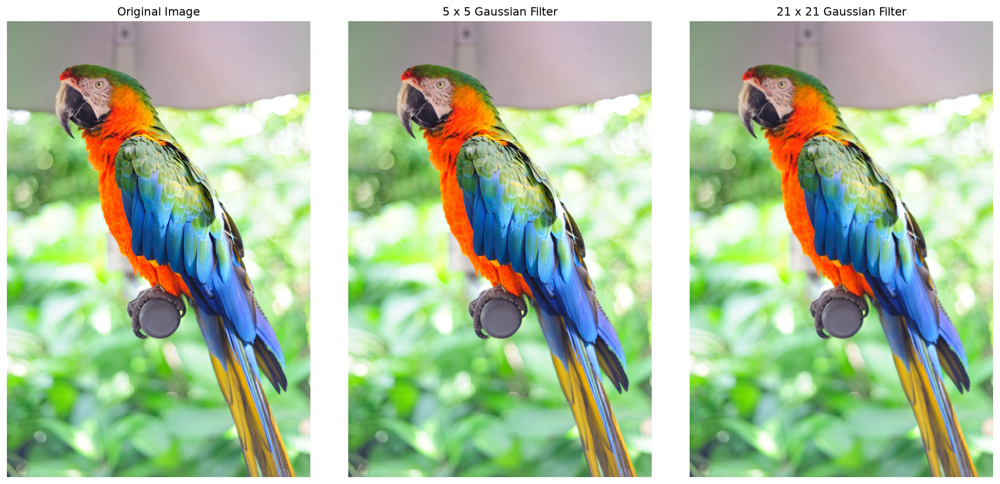

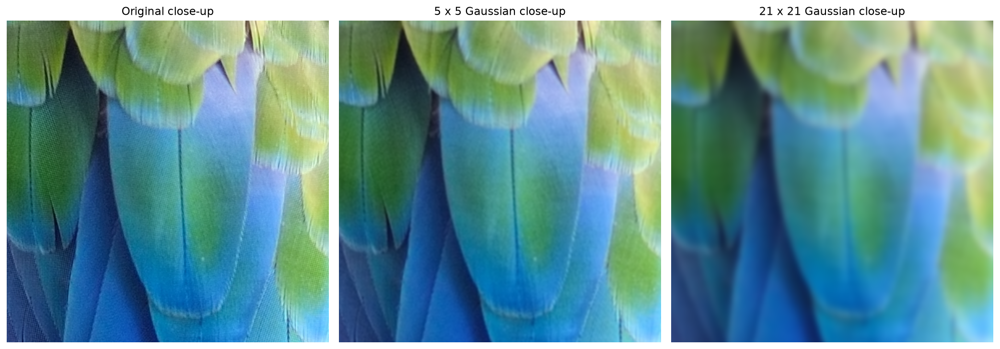

In [4]:
# Read the image and convert BGR to RGB
image = cv2.imread('images/parrot.png')
if image is None:
    raise FileNotFoundError('images/parrot.png was not found')
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
image_float = image.astype(np.float32) / 255.0

# Apply each Gaussian filter to the original image
gaussian_5 = cv2.GaussianBlur(image_float, (5, 5), sigmaX=0)
gaussian_21 = cv2.GaussianBlur(image_float, (21, 21), sigmaX=0)

fig, ax = plt.subplots(1, 3, figsize=(15, 7))
ax[0].imshow(image)
ax[0].set_title('Original Image')
ax[0].axis("off")

ax[1].imshow(np.clip(gaussian_5, 0, 1))
ax[1].set_title('5 x 5 Gaussian Filter')
ax[1].axis("off")

ax[2].imshow(np.clip(gaussian_21, 0, 1))
ax[2].set_title('21 x 21 Gaussian Filter')
ax[2].axis("off")

plt.tight_layout()
plt.show()

# Close-up of the same feather region to make the filter effect visible
x, y, size = 1100, 1350, 400
fig, ax = plt.subplots(1, 3, figsize=(15, 7))
ax[0].imshow((image)[y:y+size, x:x+size])
ax[0].set_title('Original close-up')
ax[0].axis("off")

ax[1].imshow((np.clip(gaussian_5, 0, 1))[y:y+size, x:x+size])
ax[1].set_title('5 x 5 Gaussian close-up')
ax[1].axis("off")

ax[2].imshow((np.clip(gaussian_21, 0, 1))[y:y+size, x:x+size])
ax[2].set_title('21 x 21 Gaussian close-up')
ax[2].axis("off")

plt.tight_layout()
plt.show()


## Task 3 Assessment Laplacian Sharpening
I convert the image to float32, apply cv2.Laplacian with ksize = 3, and sharpen it using the exact formula in the manual. I show the original image, the signed Laplacian response, and the sharpened image. For display, I average the three Laplacian color channels; the sharpening calculation uses all three channels.

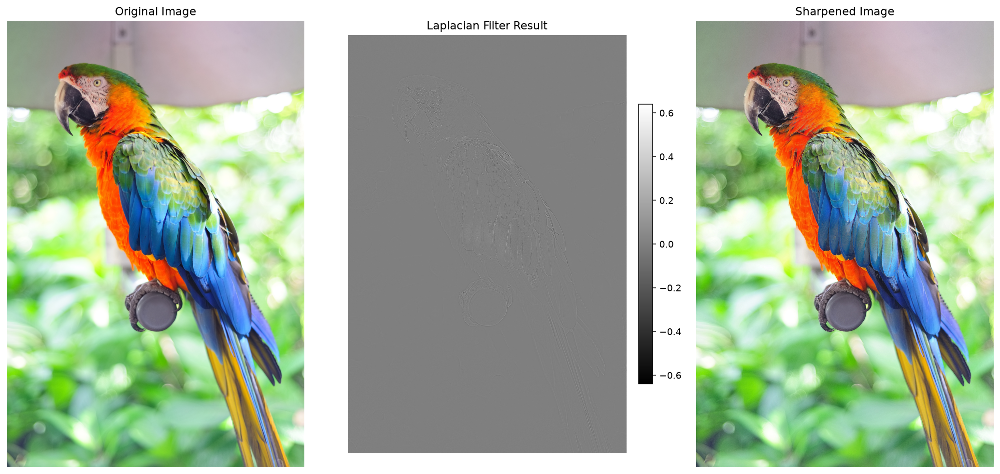

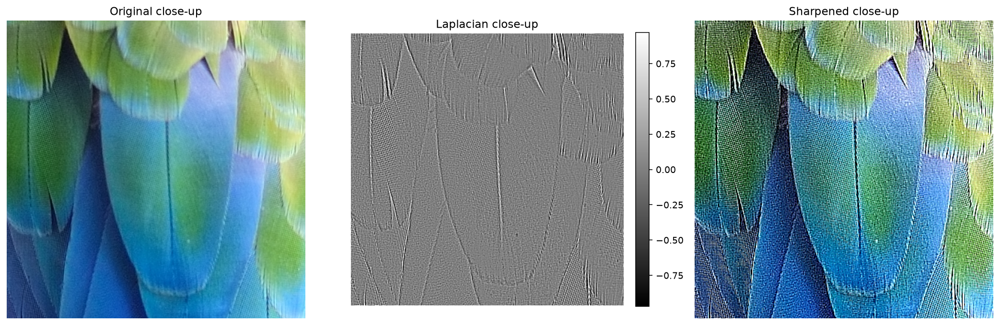

In [5]:
# Read the image and convert BGR to RGB
image = cv2.imread('images/parrot.png')
if image is None:
    raise FileNotFoundError('images/parrot.png was not found')
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
image_float = image.astype(np.float32) / 255.0

# Apply the 3 x 3 Laplacian filter
laplacian = cv2.Laplacian(image_float, cv2.CV_32F, ksize=3)

# Sharpen using the formula required in the manual
sharpened = np.clip(image_float - laplacian, 0, 1)

fig, ax = plt.subplots(1, 3, figsize=(15, 7))
ax[0].imshow(image)
ax[0].set_title('Original Image')
ax[0].axis("off")

# Show the signed Laplacian response without losing negative values.
laplacian_display = laplacian.mean(axis=2)
# Use the 99th percentile for display contrast; keep raw data for sharpening.
limit = max(float(np.percentile(np.abs(laplacian_display), 99)), 1e-8)
response = ax[1].imshow(laplacian_display, cmap='gray',
                        vmin=-limit, vmax=limit)
fig.colorbar(response, ax=ax[1], fraction=0.046, pad=0.04)
ax[1].set_title('Laplacian Filter Result')
ax[1].axis("off")

ax[2].imshow(sharpened)
ax[2].set_title('Sharpened Image')
ax[2].axis("off")

plt.tight_layout()
plt.show()

# Close-up of the same feather region to make the filter effect visible
x, y, size = 1100, 1350, 400
fig, ax = plt.subplots(1, 3, figsize=(15, 7))
ax[0].imshow((image)[y:y+size, x:x+size])
ax[0].set_title('Original close-up')
ax[0].axis("off")

# Show the signed Laplacian response without losing negative values.
laplacian_display = laplacian[y:y+size, x:x+size].mean(axis=2)
# Use the 99th percentile for display contrast; keep raw data for sharpening.
limit = max(float(np.percentile(np.abs(laplacian_display), 99)), 1e-8)
response = ax[1].imshow(laplacian_display, cmap='gray',
                        vmin=-limit, vmax=limit)
fig.colorbar(response, ax=ax[1], fraction=0.046, pad=0.04)
ax[1].set_title('Laplacian close-up')
ax[1].axis("off")

ax[2].imshow((sharpened)[y:y+size, x:x+size])
ax[2].set_title('Sharpened close-up')
ax[2].axis("off")

plt.tight_layout()
plt.show()


## Conclusion
I observed that box and Gaussian filters smooth fine texture, while Laplacian sharpening and unsharp masking increase edge contrast. The 21 x 21 Gaussian filter smooths more strongly than the 5 x 5 filter.

## References
- Student Procedural Manual Lab 5 supplied with the assignment
- https://docs.opencv.org/4.x/d4/d13/tutorial_py_filtering.html
- https://datacarpentry.github.io/image-processing/06-blurring.html